<a href="https://colab.research.google.com/github/anmoltyagi12/BigData-mnist/blob/main/mnist-preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from pathlib import Path
import cv2

Data Source

In [ ]:
url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
urllib.request.urlretrieve(url, "mnist.npz")

('mnist.npz', <http.client.HTTPMessage at 0x7d7e3a2cfac0>)

In [ ]:
with np.load("mnist.npz") as f:
    x_train, y_train = f["x_train"], f["y_train"]
    x_test, y_test = f["x_test"], f["y_test"]
    print("Training images:", x_train.shape)
    print("Training lables:", y_train.shape)
    print("Testing images:",x_test.shape)
    print("Testing labels:", y_test.shape)

    print("First image label:", y_train[5])

Training images: (60000, 28, 28)
Training lables: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
First image label: 2


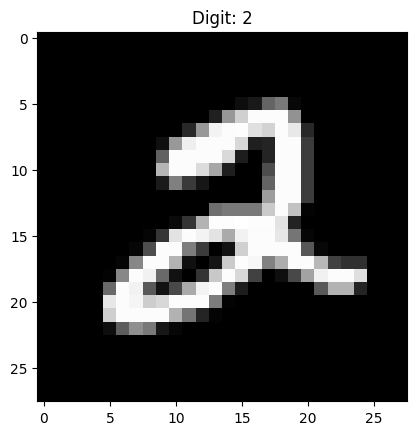

In [ ]:
plt.imshow(x_train[5], cmap="gray")
plt.title(f"Digit: {y_train[5]}")
plt.show()

In [ ]:
print("Image shape:", x_train.shape)
print("Pixel values:", x_train.min(), "to", x_train.max())
print("Unique labels:", np.unique(y_train))

Image shape: (60000, 28, 28)
Pixel values: 0 to 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]


Normalization

In [ ]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


Image shape: (28, 28)
Pixel range: 0.0 to 1.0


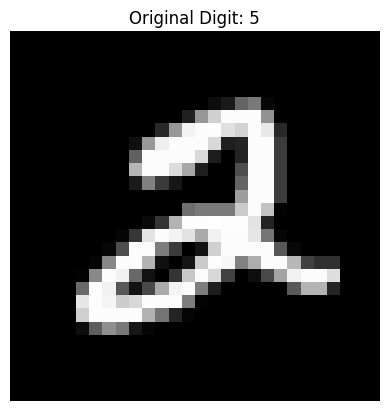

In [ ]:
image = x_train[5]

print("Image shape:", image.shape)
print("Pixel range:", image.min(), "to", image.max())

plt.imshow(image, cmap="gray")
plt.title(f"Original Digit: {y_train[0]}")
plt.axis("off")
plt.show()

Gaussian Blur

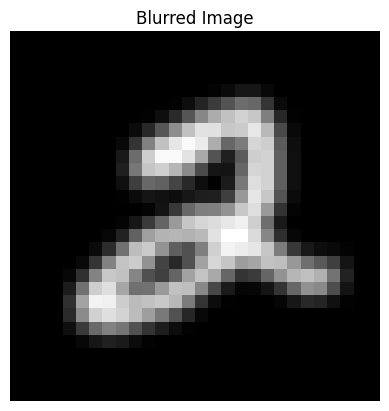

In [ ]:
import cv2
blurred = cv2.GaussianBlur(image, (3, 3), 0)

plt.imshow(blurred, cmap="gray")
plt.title("Blurred Image")
plt.axis("off")
plt.show()

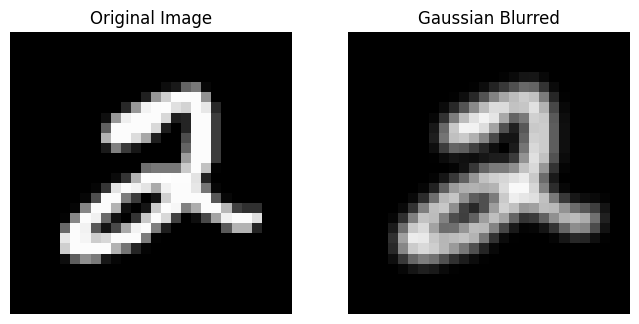

In [ ]:
blurred = cv2.GaussianBlur(image, (3, 3), 0)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred, cmap="gray", vmin=0, vmax=1)
plt.title("Gaussian Blurred")
plt.axis("off")

plt.show()

Translation

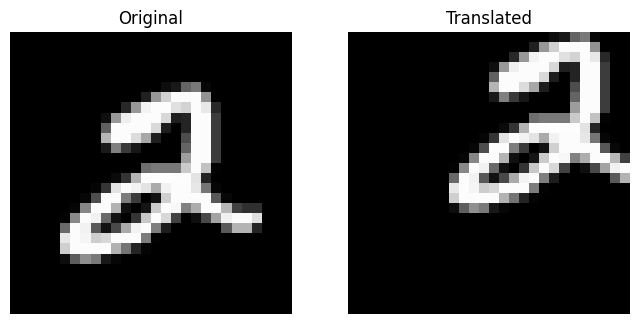

In [ ]:
def translate(image, x, y):
    trans_mat = np.float32([[1, 0, x], [0, 1, y]])
    dimension = (image.shape[1], image.shape[0])
    return cv2.warpAffine(image, trans_mat, dimension)

#translate(img, 5, 0) → right
#translate(img, -5, 0) → left
#translate(img, 0, 5) → down
#translate(img, 0, -5) → up

#shift 5 pixels right and up
trans = translate(image, 5, -5)
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(trans, cmap="gray")
plt.title("Translated")
plt.axis("off")

plt.show()

Rotation

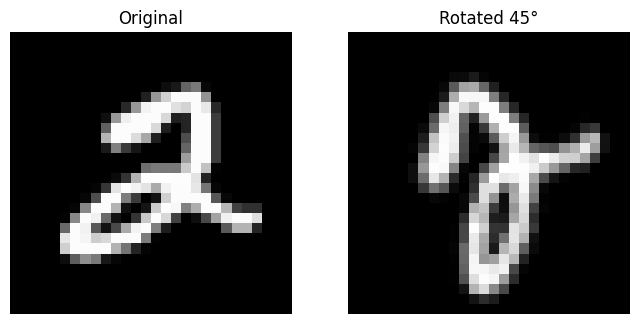

In [ ]:
def rotate(image, angle, rot_point=None):
    height, width = image.shape[:2]

    if rot_point is None:
        rot_point = (width // 2, height // 2)

    rot_mat = cv2.getRotationMatrix2D(rot_point, angle, 1.0)
    dimension = (width, height)
    return cv2.warpAffine(image, rot_mat, dimension)

rotated = rotate(image, 45)
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated, cmap="gray")
plt.title("Rotated 45°")
plt.axis("off")

plt.show()

Flipping

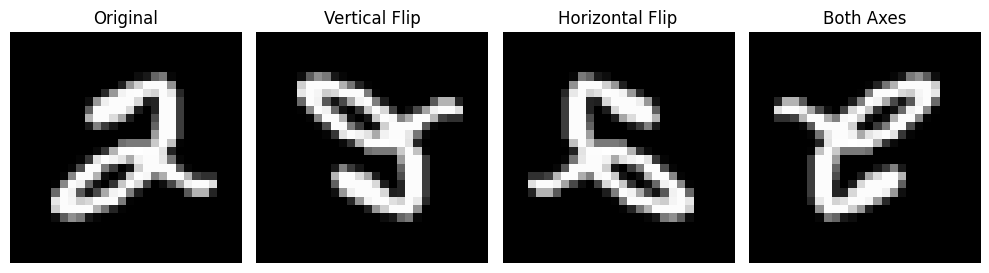

In [ ]:
# 0 = vertical, 1 = horizontal, -1 = both
flipped_vertical = cv2.flip(image, 0)
flipped_horizontal = cv2.flip(image, 1)
flipped_both = cv2.flip(image, -1)

plt.figure(figsize=(10, 3))

images = [
    (image, "Original"),
    (flipped_vertical, "Vertical Flip"),
    (flipped_horizontal, "Horizontal Flip"),
    (flipped_both, "Both Axes")
]

for i, (image, title) in enumerate(images):
    plt.subplot(1, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

Canny Edge Detection

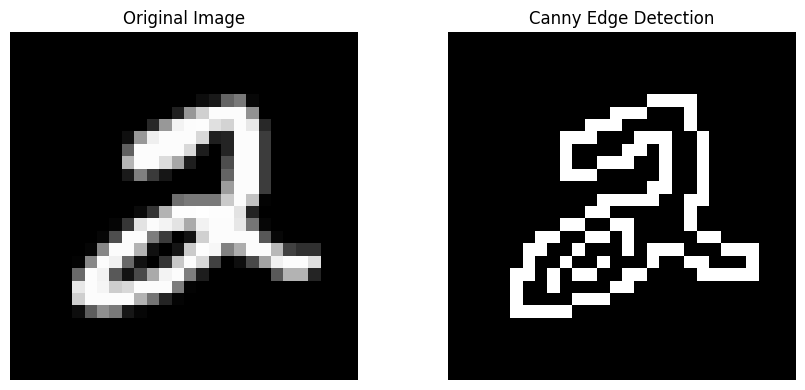

In [ ]:
img = (x_train[5] * 255).astype(np.uint8)
def edge_detection(img, threshold1, threshold2):
  # cv2.canny detects edges using gradient strength and thresholding
    edges = cv2.Canny(img, threshold1, threshold2)
    return edges
edges = edge_detection(img, 50, 150)

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

Color conversion

In [ ]:
#Grayscale to BGR
img = (x_train[5] * 255).astype(np.uint8)
def convert_to_bgr(img):
    return cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

bgr = convert_to_bgr(img)

print("Original shape:", img.shape)
print("BGR shape:", bgr.shape)

Original shape: (28, 28)
BGR shape: (28, 28, 3)


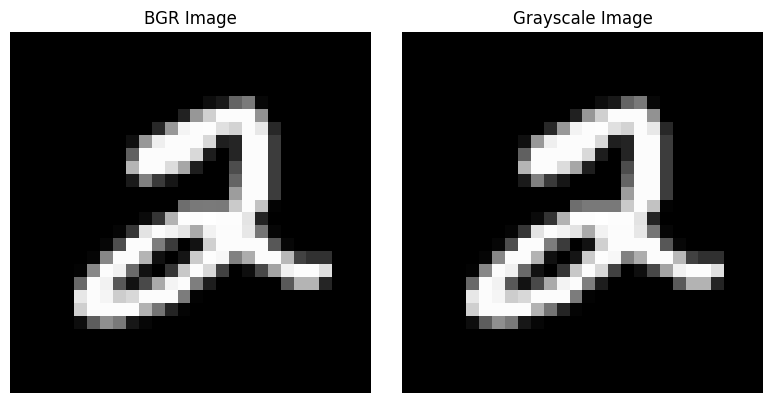

In [ ]:
#BGR to Grayscale
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(bgr[:, :, ::-1])
plt.title("BGR Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Masking

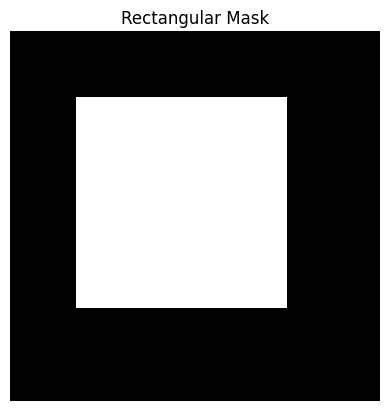

In [ ]:
img = (x_train[5] * 255).astype(np.uint8)
def create_mask(img, x1, y1, x2, y2):
    mask = np.zeros(img.shape[:2], dtype=np.uint8)
    cv2.rectangle(mask, (x1, y1), (x2, y2), 255, -1)
    return mask

mask = create_mask(img, 5, 5, 20, 20)

plt.imshow(mask, cmap="gray")
plt.title("Rectangular Mask")
plt.axis("off")
plt.show()

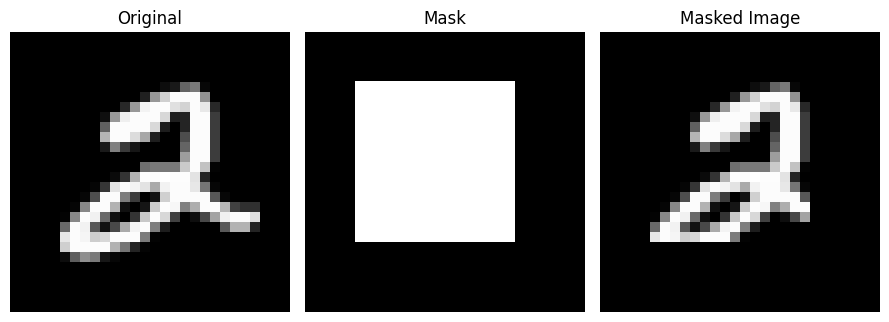

In [ ]:
masked = cv2.bitwise_and(img, img, mask=mask)

plt.figure(figsize=(9, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(masked, cmap="gray")
plt.title("Masked Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Inverse Masking

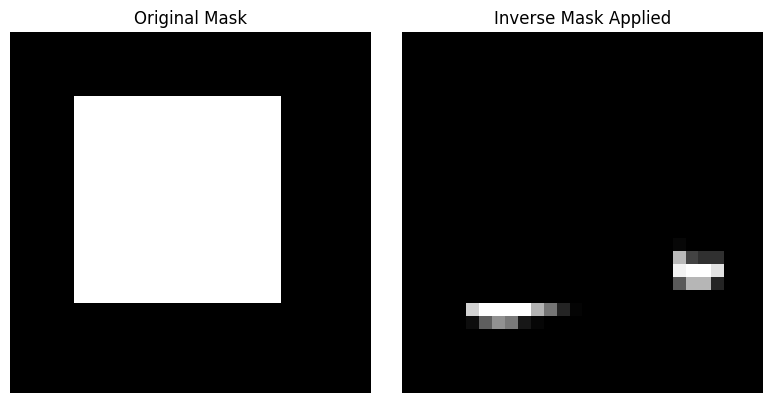

In [ ]:
inverse_mask = cv2.bitwise_not(mask)
masked_inverse = cv2.bitwise_and(img, img, mask=inverse_mask)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(masked_inverse, cmap="gray")
plt.title("Inverse Mask Applied")
plt.axis("off")

plt.tight_layout()
plt.show()

Resizing and Rescaling

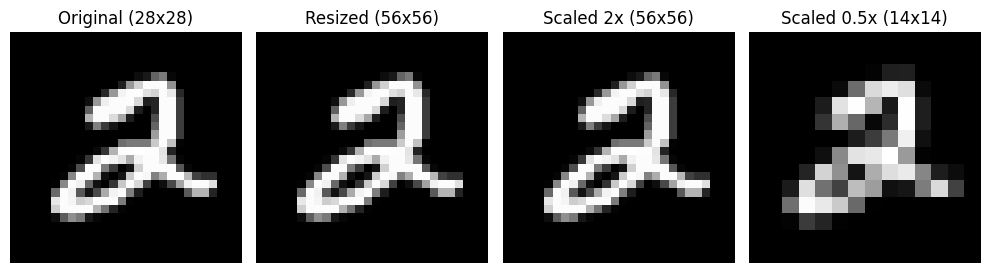

In [ ]:
img = (x_train[5] * 255).astype(np.uint8)

# Function to resize an image to specific dimensions
def resize(img, width, height):
    dimensions = (width, height)
    return cv2.resize(
        img, dimensions,
        interpolation=cv2.INTER_AREA
    )
#resizing
resized = resize(img, 56, 56)

# Function to rescale an image using scale factors
def rescale(img, scale=0.75):
    width = int(img.shape[1] * scale)
    height = int(img.shape[0] * scale)

    dimensions = (width, height)

    return cv2.resize(
        img, dimensions,
        interpolation=cv2.INTER_AREA
    )
#rescaling
scaled_up = rescale(img, 2.0)
scaled_down = rescale(img, 0.5)

images = [(img, "Original (28x28)"),(resized, "Resized (56x56)"),(scaled_up, "Scaled 2x (56x56)"),(scaled_down, "Scaled 0.5x (14x14)")]

plt.figure(figsize=(10, 5))

for i, (image, title) in enumerate(images):
    plt.subplot(1, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()